# Balanced Joint Training: Dataset 1 and Dataset 2

This notebook builds a source-balanced, one-class drone detector from `yolo26n.pt`. It preserves native exported images and labels, uses Dataset 1 and Dataset 2 training examples in equal total counts, and retains every Dataset 2 bird hard-negative frame. Dataset 1 and Dataset 2 tests remain separate.

The combined training list contains 9,507 images from each source. Dataset 1 contributes all 2,499 target-absent frames plus 7,008 temporally distributed drone-positive frames. Dataset 2 contributes all 6,138 drone-positive and 3,369 bird-negative frames.

**Evaluation scope:** the source-specific held-out test sets remain separate. Dataset 2 is the only source with bird hard negatives, so bird rejection is interpreted only there.

## Model-input resolution and labels

The raw and derived source images are never resized on disk. YOLO transforms each image in memory to a 640×640 input canvas using aspect-ratio-preserving letterboxing, and transforms normalized YOLO labels with the image. Dataset 1 is mostly 640×512; Dataset 2 is 320×256. Both share a 5:4 aspect ratio, so each receives vertical padding after scaling to the 640-pixel-wide canvas.

All labels use the same one-class format: `0 x_center y_center width height`, normalized by the source image width and height. Invalid Dataset 1 positives remain excluded; Dataset 2 birds remain empty-label no-drone examples.

In [1]:
from __future__ import annotations

from pathlib import Path
import json
import math
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from ultralytics import YOLO

WORKING_DIRECTORY = Path.cwd().resolve()
if (WORKING_DIRECTORY / '.git').is_dir():
    REPO_ROOT = WORKING_DIRECTORY
elif (WORKING_DIRECTORY.parent / '.git').is_dir():
    REPO_ROOT = WORKING_DIRECTORY.parent
else:
    raise RuntimeError('Open this notebook from the repository root or notebooks/ directory.')

THERMAL_ROOT = REPO_ROOT / 'data' / 'thermal-ir'
DATASET1_ROOT = THERMAL_ROOT / 'processed' / 'dataset1_only_yolo_v1'
DATASET2_ROOT = THERMAL_ROOT / 'processed' / 'yolo_v1'
COMBINED_ROOT = THERMAL_ROOT / 'processed' / 'combined_balanced_yolo_v1'
DATASET1_YAML = DATASET1_ROOT / 'experiment_c_dataset1_only.yaml'
DATASET2_YAML = DATASET2_ROOT / 'experiment_a_dataset2_only.yaml'
COMBINED_YAML = COMBINED_ROOT / 'combined_balanced.yaml'

RANDOM_SEED = 590
IMG_SIZE = 640
BATCH_SIZE = 32
INFERENCE_BATCH_SIZE = 8
INFERENCE_CONFIDENCE_FLOOR = 0.001
DECISION_THRESHOLDS = (0.05, 0.10, 0.25, 0.50, 0.75)
MIN_DATASET2_VALIDATION_RECALL = 0.90

EXPERIMENT_NAME = 'experiment_e_combined_balanced_yolo26n'
RUN_NAME = f'{EXPERIMENT_NAME}_batch32'
RUN_ROOT = REPO_ROOT / 'results' / 'thermal-ir' / 'runs'
EVALUATION_ROOT = REPO_ROOT / 'results' / 'thermal-ir' / 'evaluation' / RUN_NAME

print(f'Python: {sys.version.split()[0]}')
print(f'Combined derived-data root: {COMBINED_ROOT}')


Python: 3.11.7
Combined derived-data root: D:\Capstone\aai-590-capstone\data\thermal-ir\processed\combined_balanced_yolo_v1


## Build a deterministic source-balanced manifest

The source partitions are never reassigned. Dataset 1 selection is performed inside its existing training partition, with positives spread across sequence time. This reduces temporal redundancy without letting a few long videos dominate.

In [2]:
def temporal_sequence_sample(rows: pd.DataFrame, target_count: int) -> pd.DataFrame:
    """Allocate a deterministic quota per sequence, then spread selected frames across time."""
    if target_count > len(rows):
        raise ValueError('Target count exceeds candidate rows.')
    groups = [(sequence, group.sort_values('original_frame').reset_index(drop=True)) for sequence, group in rows.groupby('source_sequence', sort=True)]
    sizes = np.array([len(group) for _, group in groups], dtype=float)
    ideal = sizes / sizes.sum() * target_count
    quotas = np.floor(ideal).astype(int)
    quotas = np.minimum(quotas, sizes.astype(int))
    remaining = target_count - int(quotas.sum())
    order = sorted(range(len(groups)), key=lambda index: (ideal[index] - quotas[index], groups[index][0]), reverse=True)
    for index in order:
        if remaining == 0:
            break
        if quotas[index] < len(groups[index][1]):
            quotas[index] += 1
            remaining -= 1
    selected = []
    for quota, (_, group) in zip(quotas, groups):
        if quota:
            positions = np.linspace(0, len(group) - 1, num=quota, dtype=int)
            selected.append(group.iloc[np.unique(positions)])
    result = pd.concat(selected, ignore_index=True)
    if len(result) != target_count:
        raise RuntimeError(f'Expected {target_count} selected rows, received {len(result)}.')
    return result

def write_path_list(path: Path, rows: pd.DataFrame) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text('\n'.join(str((REPO_ROOT / image_path).resolve()) for image_path in rows.image_path) + '\n', encoding='utf-8')

dataset1_frames = pd.read_csv(DATASET1_ROOT / 'metadata' / 'frames.csv')
dataset2_all_frames = pd.read_csv(DATASET2_ROOT / 'metadata' / 'frames.csv')
dataset2_frames = dataset2_all_frames.loc[dataset2_all_frames.source_dataset.eq('drone_detection_dataset2')].copy()
d1_train = dataset1_frames.loc[dataset1_frames.split.eq('train')].copy()
d2_train = dataset2_frames.loc[dataset2_frames.split.eq('train')].copy()
d1_absent = d1_train.loc[d1_train.export_policy.eq('negative_target_absent')].copy()
d1_positive = d1_train.loc[d1_train.export_policy.eq('positive_drone')].copy()
d2_positive = d2_train.loc[d2_train.export_policy.eq('positive_drone')].copy()
d2_birds = d2_train.loc[d2_train.export_policy.eq('negative_bird')].copy()

assert len(d2_train) == 9507 and len(d2_positive) == 6138 and len(d2_birds) == 3369
assert len(d1_absent) == 2499
d1_selected_positive = temporal_sequence_sample(d1_positive, target_count=len(d2_train) - len(d1_absent))
d1_combined_train = pd.concat([d1_selected_positive, d1_absent], ignore_index=True)
assert len(d1_combined_train) == len(d2_train) == 9507

# Equal source counts for validation; retain all sparse Dataset 1 target-absent validation frames.
d1_val = dataset1_frames.loc[dataset1_frames.split.eq('val')].copy()
d2_val = dataset2_frames.loc[dataset2_frames.split.eq('val')].copy()
d1_val_absent = d1_val.loc[d1_val.export_policy.eq('negative_target_absent')].copy()
d1_val_positive = d1_val.loc[d1_val.export_policy.eq('positive_drone')].copy()
d1_selected_val_positive = temporal_sequence_sample(d1_val_positive, target_count=len(d2_val) - len(d1_val_absent))
d1_combined_val = pd.concat([d1_selected_val_positive, d1_val_absent], ignore_index=True)
assert len(d1_combined_val) == len(d2_val) == 2171

combined_train = pd.concat([d1_combined_train, d2_train], ignore_index=True).sample(frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True)
combined_val = pd.concat([d1_combined_val, d2_val], ignore_index=True).sample(frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True)
combined_manifest = pd.concat([
    combined_train.assign(combined_role='train'),
    combined_val.assign(combined_role='val'),
    dataset1_frames.loc[dataset1_frames.split.eq('test')].assign(combined_role='dataset1_test_only'),
    dataset2_frames.loc[dataset2_frames.split.eq('test')].assign(combined_role='dataset2_test_only'),
], ignore_index=True)

COMBINED_ROOT.mkdir(parents=True, exist_ok=True)
combined_manifest.to_csv(COMBINED_ROOT / 'combined_manifest.csv', index=False)
write_path_list(COMBINED_ROOT / 'splits' / 'combined_train.txt', combined_train)
write_path_list(COMBINED_ROOT / 'splits' / 'combined_val.txt', combined_val)
write_path_list(COMBINED_ROOT / 'splits' / 'dataset1_test.txt', dataset1_frames.loc[dataset1_frames.split.eq('test')])
write_path_list(COMBINED_ROOT / 'splits' / 'dataset2_test.txt', dataset2_frames.loc[dataset2_frames.split.eq('test')])
with COMBINED_YAML.open('w', encoding='utf-8') as stream:
    yaml.safe_dump({'path': str(COMBINED_ROOT), 'train': 'splits/combined_train.txt', 'val': 'splits/combined_val.txt', 'names': {0: 'drone'}}, stream, sort_keys=False)

display(combined_train.groupby(['source_dataset', 'export_policy']).size().rename('train_images').to_frame())
display(combined_val.groupby(['source_dataset', 'export_policy']).size().rename('validation_images').to_frame())


train_images
source_dataset           export_policy                       
anti_uav_dataset1        negative_target_absent          2499
                         positive_drone                  7008
drone_detection_dataset2 negative_bird                   3369
                         positive_drone                  6138

validation_images
source_dataset           export_policy                            
anti_uav_dataset1        negative_target_absent                414
                         positive_drone                       1757
drone_detection_dataset2 negative_bird                         741
                         positive_drone                       1430

## Visual check: native image versus 640×640 model canvas

Run this cell before training. The left column displays the unchanged exported image and native-normalized label. The right column displays the in-memory 640×640 letterboxed canvas and the corresponding transformed box. Gray bands are padding, not image content; no resized image is saved to the dataset.

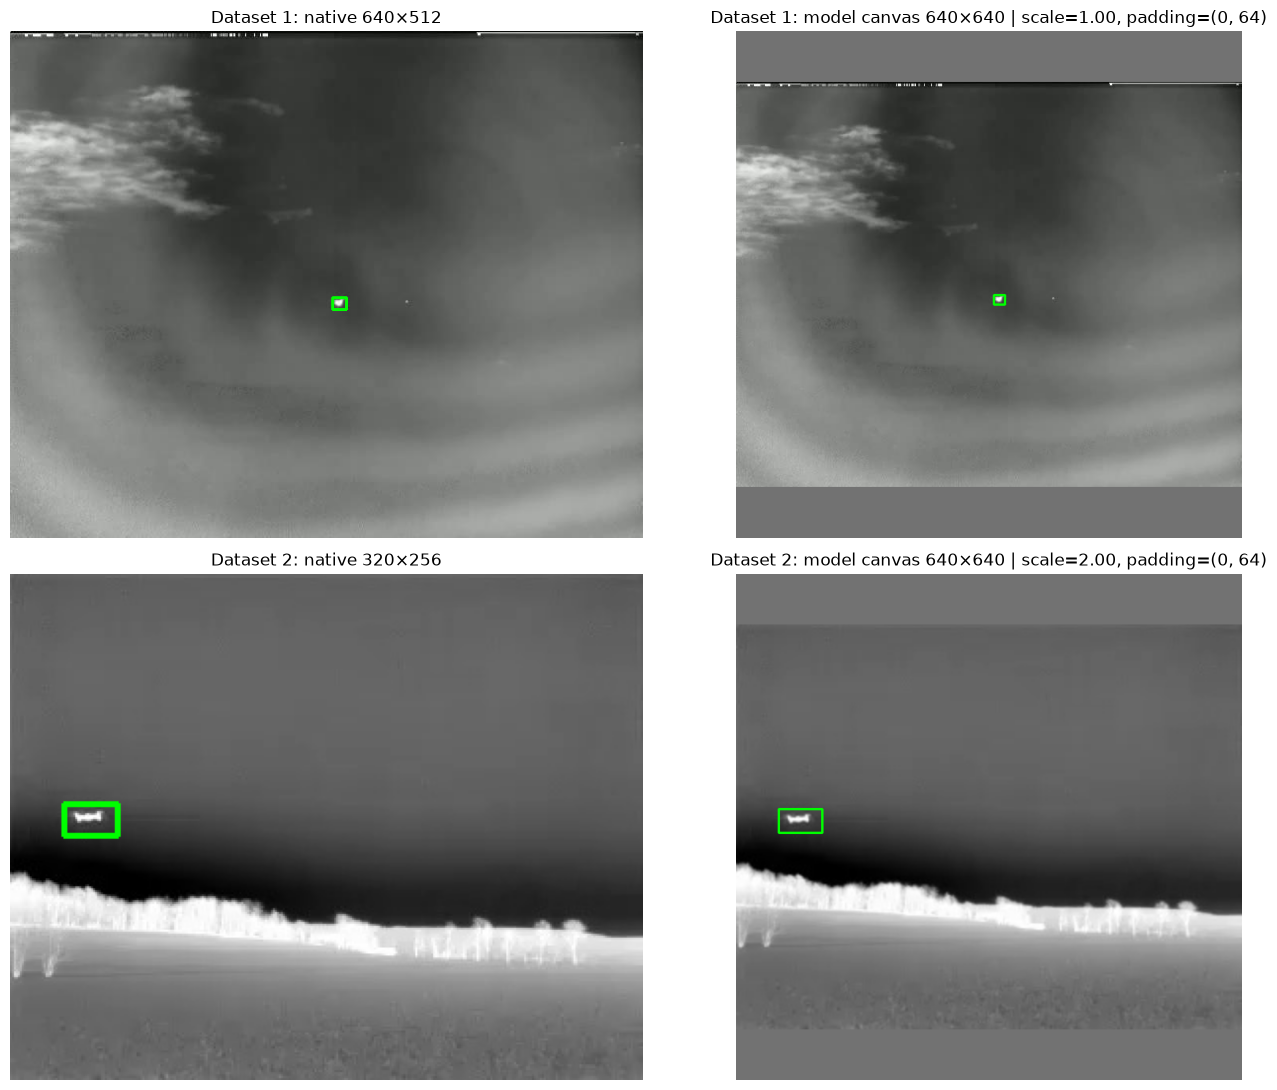

In [3]:
def read_yolo_box(label_path: Path) -> np.ndarray | None:
    content = label_path.read_text(encoding='utf-8').strip()
    if not content:
        return None
    values = [float(value) for value in content.split()]
    if len(values) != 5 or int(values[0]) != 0:
        raise ValueError(f'Unexpected label content: {label_path}')
    return np.array(values[1:], dtype=float)

def xywhn_to_xyxy(box: np.ndarray, width: int, height: int) -> np.ndarray:
    x_center, y_center, box_width, box_height = box
    return np.array([(x_center - box_width / 2) * width, (y_center - box_height / 2) * height, (x_center + box_width / 2) * width, (y_center + box_height / 2) * height])

def letterbox_with_box(image: np.ndarray, box_xyxy: np.ndarray | None, size: int = IMG_SIZE):
    height, width = image.shape[:2]
    scale = min(size / width, size / height)
    resized_width, resized_height = round(width * scale), round(height * scale)
    resized = cv2.resize(image, (resized_width, resized_height), interpolation=cv2.INTER_LINEAR)
    pad_x, pad_y = (size - resized_width) // 2, (size - resized_height) // 2
    canvas = np.full((size, size, 3), 114, dtype=np.uint8)
    canvas[pad_y:pad_y + resized_height, pad_x:pad_x + resized_width] = resized
    transformed = None if box_xyxy is None else box_xyxy * scale + np.array([pad_x, pad_y, pad_x, pad_y])
    return canvas, transformed, scale, (pad_x, pad_y)

def draw_box(image: np.ndarray, box: np.ndarray | None, color=(0, 255, 0)) -> np.ndarray:
    result = image.copy()
    if box is not None:
        x1, y1, x2, y2 = np.rint(box).astype(int)
        cv2.rectangle(result, (x1, y1), (x2, y2), color, 2)
    return result

examples = [
    ('Dataset 1', d1_combined_train.loc[d1_combined_train.export_policy.eq('positive_drone')].iloc[0]),
    ('Dataset 2', d2_train.loc[d2_train.export_policy.eq('positive_drone')].iloc[0]),
]
figure, axes = plt.subplots(2, 2, figsize=(14, 11))
for row_index, (source_name, row) in enumerate(examples):
    image = cv2.cvtColor(cv2.imread(str(REPO_ROOT / row.image_path)), cv2.COLOR_BGR2RGB)
    box = read_yolo_box(REPO_ROOT / row.label_path)
    native_box = xywhn_to_xyxy(box, image.shape[1], image.shape[0]) if box is not None else None
    model_canvas, transformed_box, scale, padding = letterbox_with_box(image, native_box)
    axes[row_index, 0].imshow(draw_box(image, native_box))
    axes[row_index, 0].set_title(f'{source_name}: native {image.shape[1]}×{image.shape[0]}')
    axes[row_index, 1].imshow(draw_box(model_canvas, transformed_box))
    axes[row_index, 1].set_title(f'{source_name}: model canvas 640×640 | scale={scale:.2f}, padding={padding}')
    for axis in axes[row_index]:
        axis.axis('off')
plt.tight_layout()
plt.show()


## Validate the combined dataset

These checks confirm that the train and validation lists have exact source counts, only valid image/label pairs, no overlap with either held-out test partition, and no sequence crossing a source split.

In [4]:
def check_rows(rows: pd.DataFrame, name: str) -> None:
    missing = [str(REPO_ROOT / value) for value in pd.concat([rows.image_path, rows.label_path]) if not (REPO_ROOT / value).is_file()]
    if missing:
        raise RuntimeError(f'{name} contains missing files, e.g. {missing[0]}')
    if rows.image_path.duplicated().any():
        raise RuntimeError(f'{name} contains duplicate image paths.')

check_rows(combined_train, 'combined train')
check_rows(combined_val, 'combined validation')
if set(combined_train.image_path) & set(combined_val.image_path):
    raise RuntimeError('Combined train/validation image overlap detected.')
test_paths = set(dataset1_frames.loc[dataset1_frames.split.eq('test'), 'image_path']) | set(dataset2_frames.loc[dataset2_frames.split.eq('test'), 'image_path'])
if (set(combined_train.image_path) | set(combined_val.image_path)) & test_paths:
    raise RuntimeError('A held-out test image appears in train or validation.')
all_rows = pd.concat([combined_train, combined_val], ignore_index=True)
sequence_splits = all_rows.groupby(['source_dataset', 'source_sequence']).split.nunique()
if (sequence_splits != 1).any():
    raise RuntimeError('A source sequence crosses an original source split.')
print(f'Combined train: {len(combined_train):,} images; validation: {len(combined_val):,} images')
print('Integrity checks passed.')


Combined train: 19,014 images; validation: 4,342 images
Integrity checks passed.


## Train from generic YOLO weights

This is a fresh thermal training run initialized from generic `yolo26n.pt`, not from Dataset 1 or Dataset 2 weights. It uses the source-balanced training and validation lists above.

Before training, shut down other GPU notebook kernels. Do not overwrite an existing run directory.

In [5]:
if not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Shut down other GPU-using notebook kernels, then restart this kernel.')

TRAIN_CONFIG = {
    'imgsz': IMG_SIZE, 'epochs': 100, 'batch': BATCH_SIZE, 'device': 0,
    'optimizer': 'AdamW', 'lr0': 1e-3, 'weight_decay': 5e-4, 'patience': 20,
    'seed': RANDOM_SEED, 'deterministic': True, 'workers': 8, 'pretrained': True, 'resume': False, 'cache': False,
    'hsv_h': 0.0, 'hsv_s': 0.0, 'hsv_v': 0.0, 'fliplr': 0.5, 'flipud': 0.0,
    'degrees': 0.0, 'translate': 0.10, 'scale': 0.25, 'mosaic': 0.5, 'close_mosaic': 10,
}

def train_combined() -> Path:
    run_directory = RUN_ROOT / RUN_NAME
    if run_directory.exists():
        raise RuntimeError(f'{run_directory} already exists. Choose a new name; do not overwrite an experiment.')
    model = YOLO('yolo26n.pt')
    model.train(data=str(COMBINED_YAML), project=str(RUN_ROOT), name=RUN_NAME, exist_ok=False, **TRAIN_CONFIG)
    return Path(model.trainer.save_dir)


In [6]:
# Run once after reviewing the manifest counts and resize visualization.
training_run_dir = train_combined()
BEST_WEIGHTS = training_run_dir / 'weights' / 'best.pt'
if not BEST_WEIGHTS.is_file():
    raise RuntimeError(f'Expected best checkpoint was not written: {BEST_WEIGHTS}')
print(f'Combined-model checkpoint: {BEST_WEIGHTS}')


New https://pypi.org/project/ultralytics/8.4.213 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.198  Python-3.11.7 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5080, 16276MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Capstone\aai-590-capstone\data\thermal-ir\processed\combined_balanced_yolo_v1\combined_balanced.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001,

## Select the Dataset 2 threshold and test each source

The decision threshold is selected from Dataset 2 validation only, retaining the original project priority: minimize bird false positives while requiring at least 90% Dataset 2 validation recall. The selected threshold is then locked for Dataset 1 and Dataset 2 tests. Object-detection metrics and image decisions are saved in separate source folders.

Inference is explicitly chunked to eight images at a time so the evaluation fits the GPU.

In [7]:
def predict_scores(model: YOLO, rows: pd.DataFrame) -> pd.DataFrame:
    records, scored = rows.to_dict('records'), []
    for start in range(0, len(records), INFERENCE_BATCH_SIZE):
        batch_rows = records[start:start + INFERENCE_BATCH_SIZE]
        paths = [str((REPO_ROOT / row['image_path']).resolve()) for row in batch_rows]
        predictions = list(model.predict(paths, stream=True, conf=INFERENCE_CONFIDENCE_FLOOR, device=0, verbose=False))
        if len(predictions) != len(batch_rows):
            raise RuntimeError('Prediction count did not match the requested image batch.')
        for row, prediction in zip(batch_rows, predictions):
            confidences = [float(value) for value in prediction.boxes.conf]
            scored.append({**row, 'ground_truth_drone_present': row['label_status'] == 'drone_positive', 'max_confidence': max(confidences, default=0.0)})
        del predictions
        torch.cuda.empty_cache()
    return pd.DataFrame(scored)

def summarize(scores: pd.DataFrame, threshold: float) -> tuple[pd.DataFrame, dict]:
    decisions = scores.copy(); decisions['predicted_drone_present'] = decisions.max_confidence.ge(threshold)
    decisions['binary_outcome'] = np.select([decisions.ground_truth_drone_present & decisions.predicted_drone_present, ~decisions.ground_truth_drone_present & decisions.predicted_drone_present, decisions.ground_truth_drone_present & ~decisions.predicted_drone_present], ['true_positive', 'false_positive', 'false_negative'], default='true_negative')
    counts = decisions.binary_outcome.value_counts(); tp=int(counts.get('true_positive',0)); fp=int(counts.get('false_positive',0)); fn=int(counts.get('false_negative',0)); tn=int(counts.get('true_negative',0))
    precision=tp/(tp+fp) if tp+fp else 0.0; recall=tp/(tp+fn) if tp+fn else 0.0
    return decisions, {'decision_threshold':threshold,'true_positive':tp,'false_positive':fp,'false_negative':fn,'true_negative':tn,'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.0,'negative_false_positive_rate':fp/(fp+tn) if fp+tn else 0.0}

# In a fresh kernel, skip the training cell and use this saved path instead.
BEST_WEIGHTS = RUN_ROOT / RUN_NAME / 'weights' / 'best.pt'
if not BEST_WEIGHTS.is_file():
    raise FileNotFoundError(f'Combined-model checkpoint is missing: {BEST_WEIGHTS}')
torch.cuda.empty_cache(); model = YOLO(str(BEST_WEIGHTS)); EVALUATION_ROOT.mkdir(parents=True, exist_ok=True)

d2_validation_scores = predict_scores(model, d2_val.reset_index(drop=True))
threshold_report = pd.DataFrame([summarize(d2_validation_scores, threshold)[1] for threshold in DECISION_THRESHOLDS])
eligible = threshold_report.loc[threshold_report.recall.ge(MIN_DATASET2_VALIDATION_RECALL)]
threshold_choice = (eligible if not eligible.empty else threshold_report).sort_values(['negative_false_positive_rate','f1','decision_threshold'], ascending=[True,False,False]).iloc[0]
DECISION_THRESHOLD = float(threshold_choice.decision_threshold)
d2_validation_scores.to_csv(EVALUATION_ROOT / 'dataset2_validation_scores.csv', index=False)
threshold_report.to_csv(EVALUATION_ROOT / 'dataset2_validation_threshold_report.csv', index=False)
display(threshold_report); print(f'Locked Dataset 2 validation threshold: {DECISION_THRESHOLD:.2f}')


,decision_threshold,true_positive,false_positive,false_negative,true_negative,precision,recall,f1,negative_false_positive_rate
0,0.05,1430,12,0,729,0.991678,1.000000,0.995822,0.016194
1,0.10,1430,8,0,733,0.994437,1.000000,0.997211,0.010796
2,0.25,1430,3,0,738,0.997906,1.000000,0.998952,0.004049
3,0.50,1366,1,64,740,0.999268,0.955245,0.976761,0.001350
4,0.75,1,0,1429,741,1.000000,0.000699,0.001398,0.000000


Locked Dataset 2 validation threshold: 0.50


In [8]:
def evaluate_test(source_name: str, data_yaml: Path, rows: pd.DataFrame) -> dict:
    root = EVALUATION_ROOT / source_name; root.mkdir(parents=True, exist_ok=True)
    detection = model.val(data=str(data_yaml), split='test', conf=INFERENCE_CONFIDENCE_FLOOR, batch=INFERENCE_BATCH_SIZE, device=0, plots=True, project=str(root), name='ultralytics_detection', exist_ok=True)
    metrics = detection.results_dict; (root / 'test_detection_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    del detection; torch.cuda.empty_cache()
    scores = predict_scores(model, rows.loc[rows.split.eq('test')].reset_index(drop=True))
    decisions, decision_metrics = summarize(scores, DECISION_THRESHOLD)
    if source_name == 'dataset2_test':
        birds = decisions.export_policy.eq('negative_bird'); decision_metrics['bird_false_positive_rate'] = float(decisions.loc[birds, 'predicted_drone_present'].mean())
    else:
        decision_metrics['limitation'] = 'Dataset 1 target-absent frames are background negatives, not birds.'
    decision_metrics['threshold_selected_on'] = 'dataset2_validation_only'
    scores.to_csv(root / 'test_image_scores.csv', index=False); decisions.to_csv(root / 'test_image_decisions.csv', index=False)
    (root / 'test_decision_metrics.json').write_text(json.dumps(decision_metrics, indent=2), encoding='utf-8')
    return {'source':source_name, **metrics, **decision_metrics}

dataset1_summary = evaluate_test('dataset1_test', DATASET1_YAML, dataset1_frames)
dataset2_summary = evaluate_test('dataset2_test', DATASET2_YAML, dataset2_frames)
comparison = pd.DataFrame([dataset1_summary, dataset2_summary]).set_index('source')
comparison.to_csv(EVALUATION_ROOT / 'source_specific_test_comparison.csv')
display(comparison.T)


Ultralytics 8.4.198  Python-3.11.7 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5080, 16276MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.3±0.1 ms, read: 15.6±9.7 MB/s, size: 59.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\Capstone\aai-590-capstone\data\thermal-ir\processed\dataset1_only_yolo_v1\labels\test.cache... 7242 images, 610 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 7242/7242  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 906/906 23.6it/s 38.4s0.1ss
                   all       7242       6632      0.884      0.676      0.746      0.381
Speed: 0.5ms preprocess, 1.0ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to D:\Capstone\aai-590-capstone\results\thermal-ir\evaluation\experiment_e_combi

source,dataset1_test,dataset2_test
metrics/precision(B),0.883854,0.889568
metrics/recall(B),0.676116,0.890309
metrics/mAP50(B),0.746193,0.878251
metrics/mAP50-95(B),0.380851,0.401196
fitness,0.380851,0.401196
decision_threshold,0.5,0.5
true_positive,4382,1765
false_positive,6,0
false_negative,2250,113
true_negative,604,753


## Completed-run interpretation

**Run:** `experiment_e_combined_balanced_yolo26n_batch32` (2026-11-14). Training early-stopped after 32 epochs; the selected checkpoint was epoch 12, with balanced-validation mAP@0.5 of 79.87% and mAP@0.5:0.95 of 41.49%. The Dataset 2 validation procedure selected a decision threshold of **0.50**: it retained 95.52% validation recall while reducing bird-negative false positives to 0.13%.

| Held-out source | Detection mAP@0.5 | Detection mAP@0.5:0.95 | Image-level recall at 0.50 | Negative false-positive rate |
| --- | ---: | ---: | ---: | ---: |
| Dataset 1 test | 74.62% | 38.09% | 66.07% | 0.98% target-absent backgrounds |
| Dataset 2 test | 87.83% | 40.12% | 93.98% | 0.00% birds |

The balanced combined model is a successful cross-source detector: unlike Dataset 2-only training, it can detect Dataset 1 targets while retaining Dataset 2 detection quality and bird rejection. It did not surpass the Dataset 1-only detector on Dataset 1 localization (77.27% mAP@0.5) and it did not surpass the Dataset 2-only baseline's Dataset 2 image-level recall/F1 under that baseline's own 0.25 threshold (97.44% recall, 98.57% F1). Therefore, select the final model according to scope: the Dataset 2-only model remains the strongest choice for the project's drone-versus-bird deployment question; this combined model is the defensible choice when explicitly claiming coverage of both source domains.

Do not use either held-out test result to select another checkpoint or threshold. Dataset 1 target-absent frames are not bird hard negatives, so their false-positive rate must not be described as a bird false-positive rate.